<a href="https://colab.research.google.com/github/Bremcm/khpi-python-labs/blob/main/Lab4_Data_Visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4
## Дослідження та візуалізація даних за допомогою Python

**Виконав:** студент групи КН-425, Владислав Тимошенко

**Мета роботи:** отримати базові навики використання Python для дослідження та візуалізації даних.

**Набір даних:** `russia_losses_equipment.csv` з [Kaggle](https://www.kaggle.com/datasets/piterfm/2022-ukraine-russian-war) — накопичувальні дані про втрати техніки за кожну дату.

In [42]:
# Визначення номера варіанта за першою літерою прізвища (Tymoshenko -> T)
N = ord("T") % 3 + 1
N

1

## Варіант 1. Дослідження втрат літаків
1. Створити функцію, яка приймає назву файлу та назву стовпця і повертає масив зі значеннями стовпця.
2. Створити масив numpy зі значень стовпця «aircraft».
3. Знайти добові втрати літаків.
4. Знайти 3 найбільші добові втрати літаків.
5. Визначити, скільки літаків було збито влітку 2022 року.
6. Знайти середнє значення втрат авіації за останні 300 днів війни.
7. Побудувати графік втрат літаків за перший рік війни.

In [43]:
import csv
import glob
import shutil

import numpy as np
import matplotlib.pyplot as plt

FILE = "russia_losses_equipment.csv"

In [44]:
import kagglehub

path = kagglehub.dataset_download("piterfm/2022-ukraine-russian-war")
matches = glob.glob(f"{path}/**/{FILE}", recursive=True)
shutil.copy(matches[0], FILE)

print("Файл скопійовано:", FILE)

Using Colab cache for faster access to the '2022-ukraine-russian-war' dataset.
Файл скопійовано: russia_losses_equipment.csv


In [45]:
with open(FILE, encoding="utf-8") as f:
    print(f.read(400))

date,day,aircraft,helicopter,tank,APC,field artillery,MRL,military auto,fuel tank,drone,naval ship,anti-aircraft warfare,special equipment,mobile SRBM system,greatest losses direction,vehicles and fuel tanks,cruise missiles,submarines,ground robotic systems
2026-11-14,1725,452,356,12478,25750,52355,2273,,,607531,35,1756,4905.0,,,174609.0,5196.0,2.0,3140.0
2026-11-12,1723,452,356,12472,25731,52322,


### Завдання 1. Функція читання стовпця
Функція `read_column(filename, column, dtype)` читає CSV-файл за допомогою `csv.reader()`, пропускає рядок заголовків і повертає масив numpy зі значеннями вказаного стовпця. Порожні значення в числових стовпцях замінюються на `NaN`.

In [46]:
def read_column(filename, column, dtype=float):
    with open(filename, encoding="utf-8") as f:
        reader = csv.reader(f)
        header = next(reader)

        if column not in header:
            raise ValueError(f"Стовпця '{column}' немає у файлі")

        idx = header.index(column)
        values = np.array([row[idx] for row in reader])

    if dtype is float:
        values = np.where(values == "", "nan", values)

    return values.astype(dtype)

### Завдання 2. Масив значень стовпця «aircraft»
Дані у файлі впорядковані від найновішої дати до найстарішої, тому масиви сортуються за датою за зростанням.

In [47]:
dates = read_column(FILE, "date", dtype="datetime64[D]")
aircraft = read_column(FILE, "aircraft")

order = np.argsort(dates)
dates = dates[order]
aircraft = aircraft[order].astype(int)

print("Перша дата:", dates[0], "| накопичено:", aircraft[0])
print("Остання дата:", dates[-1], "| накопичено:", aircraft[-1])
print("Записів у файлі:", dates.size)

total_days = (dates[-1] - dates[0]).astype(int) + 1
print("Днів у періоді:", total_days, "| пропущених дат:", total_days - dates.size)

aircraft

Перша дата: 2022-02-25 | накопичено: 10
Остання дата: 2026-11-14 | накопичено: 452
Записів у файлі: 1724
Днів у періоді: 1724 | пропущених дат: 0


array([ 10,  27,  27, ..., 452, 452, 452], shape=(1724,))

### Завдання 3. Добові втрати літаків
Дані у файлі накопичувальні, тому добові втрати — це різниця між сусідніми значеннями. Для першого дня беремо саме накопичене значення (втрати з початку війни до першої дати в наборі даних).

In [48]:
def daily_losses(cumulative):
    return np.diff(cumulative, prepend=0)


aircraft_daily = daily_losses(aircraft)

print("Добові втрати (перші 10 днів):", aircraft_daily[:10])
print("Сума добових втрат:", aircraft_daily.sum(), "| остання накопичена:", aircraft[-1])
print("Від'ємних значень (коригування даних):", np.count_nonzero(aircraft_daily < 0))

Добові втрати (перші 10 днів): [10 17  0  2  0  1  0  3  6  5]
Сума добових втрат: 452 | остання накопичена: 452
Від'ємних значень (коригування даних): 2


### Завдання 4. Три найбільші добові втрати літаків

In [49]:
def top_losses(daily, dates, k=3):
    idx = np.argsort(daily, kind="stable")[::-1][:k]
    return daily[idx], dates[idx]


top_values, top_dates = top_losses(aircraft_daily, dates, k=3)

print("3 найбільші добові втрати:", top_values)
print("Дати:", top_dates)

3 найбільші добові втрати: [41 17 16]
Дати: ['2025-06-03' '2022-02-26' '2022-03-13']


In [50]:
neg_mask = aircraft_daily < 0
print("Дати коригувань:", dates[neg_mask])
print("Значення:", aircraft_daily[neg_mask])

Дати коригувань: ['2023-10-03' '2024-10-03']
Значення: [-1 -1]


### Завдання 5. Кількість літаків, збитих влітку 2022 року
Літо 2022 року — з 1 червня по 31 серпня включно.

In [51]:
def losses_in_period(daily, dates, start, end):
    mask = (dates >= np.datetime64(start)) & (dates <= np.datetime64(end))
    return daily[mask].sum()


summer_2022 = losses_in_period(aircraft_daily, dates, "2022-06-01", "2022-08-31")
print("Влітку 2022 року збито літаків:", summer_2022)

Влітку 2022 року збито літаків: 26


### Завдання 6. Середнє значення втрат авіації за останні 300 днів війни

In [52]:
def mean_last_days(daily, dates, days=300):
    start = dates[-1] - np.timedelta64(days - 1, "D")
    return daily[dates >= start].mean()


mean_300 = mean_last_days(aircraft_daily, dates, days=300)
print(f"Середні добові втрати літаків за останні 300 днів: {mean_300:.3f}")

Середні добові втрати літаків за останні 300 днів: 0.060


### Завдання 7. Графік втрат літаків за перший рік війни
Період — 365 днів, починаючи з першої дати в наборі даних. На верхньому графіку — накопичувальні втрати, на нижньому — добові.

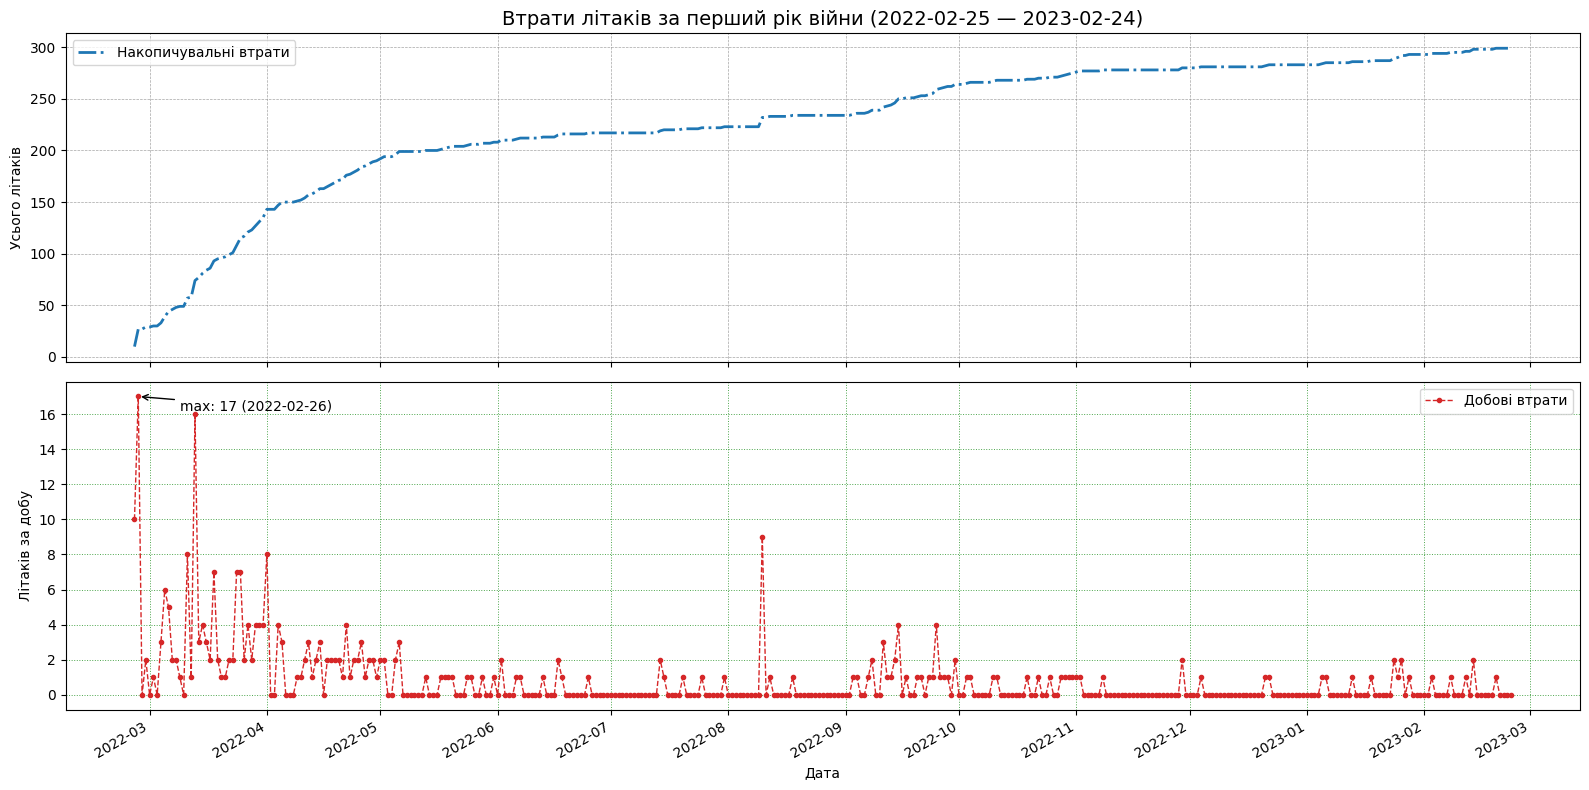

'aircraft_first_year.png'

In [53]:
import matplotlib.dates as mdates


def plot_losses(daily, cumulative, dates, days=365, filename="aircraft_first_year.png"):
    end = dates[0] + np.timedelta64(days, "D")
    mask = dates < end
    d, daily_p, cum_p = dates[mask], daily[mask], cumulative[mask]

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 8), dpi=100, sharex=True)

    # Накопичувальні втрати
    ax1.plot(d, cum_p, color="tab:blue", linestyle="-.", linewidth=2,
             label="Накопичувальні втрати")
    ax1.set_title(f"Втрати літаків за перший рік війни ({d[0]} — {d[-1]})", fontsize=14)
    ax1.set_ylabel("Усього літаків")
    ax1.grid(True, color="gray", linestyle="--", linewidth=0.5, alpha=0.7)
    ax1.legend(loc="upper left")

    # Добові втрати
    ax2.plot(d, daily_p, color="tab:red", linestyle="--", marker="o", markersize=3,
             linewidth=1, label="Добові втрати")
    i_max = np.argmax(daily_p)
    ax2.annotate(f"max: {daily_p[i_max]} ({d[i_max]})",
                 xy=(d[i_max], daily_p[i_max]),
                 xytext=(30, -10), textcoords="offset points",
                 arrowprops=dict(arrowstyle="->"))
    ax2.set_xlabel("Дата")
    ax2.set_ylabel("Літаків за добу")
    ax2.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax2.grid(True, color="green", linestyle=":", linewidth=0.7, alpha=0.7)
    ax2.legend(loc="upper right")

    # Позначки на осі дат — щомісяця
    ax2.xaxis.set_major_locator(mdates.MonthLocator())
    ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    fig.autofmt_xdate()

    fig.tight_layout()
    fig.savefig(filename, dpi=100)
    plt.show()
    return filename


plot_losses(aircraft_daily, aircraft, dates)

## Висновки

У ході роботи було досліджено дані про втрати літаків із набору `russia_losses_equipment.csv` з використанням бібліотек **numpy** та **matplotlib**.

- Дані у файлі накопичувальні та впорядковані не за датою, тому масиви було відсортовано через `np.argsort`, а добові втрати обчислено як різницю сусідніх значень (`np.diff`).
- У даних виявлено 2 від'ємні добові значення — коригування накопиченої кількості джерелом даних; їх збережено, оскільки сума добових втрат має збігатися з підсумковою.
- Найбільші добові втрати: 41, 17 і 16 літаків.
- Влітку 2022 року збито 26 літаків.
- Середні добові втрати за останні 300 днів: 0.060.
- Побудовано графік втрат за перший рік війни та збережено його у файл PNG.

Усю обробку масивів виконано без циклів — за допомогою зрізів, булевих масок і векторизованих функцій numpy.